# Machine Learning-Based Tuberculosis Risk Prediction for Early Screening

## Predictive Analytics – CA3

### Objective
To develop a machine learning model that predicts TB risk using
clinical and demographic data, supporting early screening and
further clinical assessment.

### KDD / Predictive Modelling Pipeline
Problem Identification → Data Selection → Data Understanding →
Data Cleaning → Exploratory Data Analysis → Feature Engineering →
Model Development → Model Evaluation → Interpretation

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

In [4]:
df = pd.read_csv("peerj-cs-10-2397-s002.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (999, 26)


,Patient ID,DATASET RELATED TO TB DISEASE,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Prediction,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,NaN,"FEATURES: EARLY SIGNS, SYMPTOMS AND RISK FACTO...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Cough,Cough Duration,Cough Type,Mucus,Chest Pain,Breathe State,Body Temperature,Chills,Pulmonary Effusion,...,Exposed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,No,0,No,No,Yes,Normal,Normal,No,No,...,Yes,Not Suspected,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2.0,No,0,No,No,Normal,Normal,Normal,No,No,...,Yes,Not Suspected,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3.0,No,0,Non Productive,No,Yes,Normal,Normal,No,No,...,No,Not Suspected,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.head(10)

df.info()

Rows: 999
Columns: 26

Column names:
['Patient ID', 'DATASET RELATED TO TB DISEASE ', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Prediction', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Patient ID                      760 non-null    float64
 1   DATASET RELATED TO TB DISEASE   762 non-null    object 
 2   Unnamed: 2                      761 non-null    object 
 3   Unnamed: 3                      761 non-null    object 
 4   Unnamed: 4                      761 non-null    object 
 5   Unnamed: 5                

In [6]:
data = df[
    df["Patient ID"].notna() &
    df["Prediction"].notna()
].copy()

print("Clean dataset shape:", data.shape)

Clean dataset shape: (760, 26)


In [7]:
data = data.iloc[:, :18].copy()

data.columns = [
    "Patient ID",
    "Cough",
    "Cough Duration",
    "Cough Type",
    "Mucus",
    "Chest Pain",
    "Breathe State",
    "Body Temperature",
    "Chills",
    "Pulmonary Effusion",
    "ESR Value",
    "Diet",
    "Physique",
    "Energy Adequacy",
    "Smoking",
    "Crowding",
    "Exposed",
    "Prediction"
]

data.head()

,Patient ID,Cough,Cough Duration,Cough Type,Mucus,Chest Pain,Breathe State,Body Temperature,Chills,Pulmonary Effusion,ESR Value,Diet,Physique,Energy Adequacy,Smoking,Crowding,Exposed,Prediction
2,1.0,No,0,No,No,Yes,Normal,Normal,No,No,Normal,Malnutrition,Weight Loss,Fatigue,Yes,Yes,Yes,Not Suspected
3,2.0,No,0,No,No,Normal,Normal,Normal,No,No,Disturbed,Malnutrition,Weight Loss,Fatigue,No,Yes,Yes,Not Suspected
4,3.0,No,0,Non Productive,No,Yes,Normal,Normal,No,No,Disturbed,Malnutrition,Healthy,Fit,Yes,Yes,No,Not Suspected
5,4.0,No,0,No,No,Yes,Dyspnea,Normal,No,No,Normal,Balanced,Weight Loss,Fit,Yes,Yes,No,Not Suspected
6,5.0,No,0,No,No,Normal,Normal,High,No,No,Normal,Malnutrition,Weight Loss,Fatigue,No,Yes,Yes,Not Suspected


In [8]:
print(data["Prediction"].value_counts())

print("\nPercentage distribution:")
print(data["Prediction"].value_counts(normalize=True) * 100)

Prediction
TB Suspected     392
Not Suspected    368
Name: count, dtype: int64

Percentage distribution:
Prediction
TB Suspected     51.578947
Not Suspected    48.421053
Name: proportion, dtype: float64


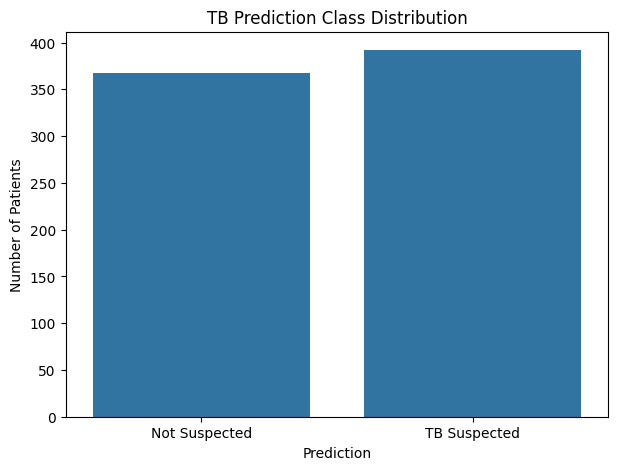

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="Prediction"
)

plt.title("TB Prediction Class Distribution")
plt.xlabel("Prediction")
plt.ylabel("Number of Patients")

plt.show()

In [10]:
missing = data.isnull().sum()

print(missing)

print("Total missing values:", data.isnull().sum().sum())

Patient ID            0
Cough                 0
Cough Duration        0
Cough Type            0
Mucus                 0
Chest Pain            0
Breathe State         0
Body Temperature      0
Chills                0
Pulmonary Effusion    0
ESR Value             0
Diet                  0
Physique              0
Energy Adequacy       0
Smoking               0
Crowding              0
Exposed               0
Prediction            0
dtype: int64
Total missing values: 0


In [11]:
print("Duplicate rows:", data.duplicated().sum())

data = data.drop_duplicates()

print("Dataset shape after removing duplicates:", data.shape)

Duplicate rows: 0
Dataset shape after removing duplicates: (760, 18)


In [12]:
print("Number of patients:", len(data))
print("Number of features:", len(data.columns) - 2)
print("Target variable: Prediction")

print("\nTarget classes:")
print(data["Prediction"].unique())

Number of patients: 760
Number of features: 16
Target variable: Prediction

Target classes:
['Not Suspected' 'TB Suspected']


In [13]:
# Dataset information

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nTarget Distribution:")
print(df["Prediction"].value_counts())

Dataset Shape: (999, 26)

Column Names:
['Patient ID', 'DATASET RELATED TO TB DISEASE ', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Prediction', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']

Data Types:
Patient ID                        float64
DATASET RELATED TO TB DISEASE      object
Unnamed: 2                         object
Unnamed: 3                         object
Unnamed: 4                         object
Unnamed: 5                         object
Unnamed: 6                         object
Unnamed: 7                         object
Unnamed: 8                         object
Unnamed: 9                         object
Unnamed: 10                        object
Unnamed: 11                        object
Unnamed: 12                        object
U

In [14]:
# Cell 12: Cough Duration Distribution

# Clean all column names
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.replace("\n", " ", regex=False)
)

# Find the cough duration column
cough_duration_col = None

for col in df.columns:
    if "cough" in col.lower() and "duration" in col.lower():
        cough_duration_col = col
        break

# Check whether the column was found
if cough_duration_col is None:
    print("Cough Duration column was not found.")
    print("Available columns:")
    print(df.columns.tolist())
else:
    print("Using column:", cough_duration_col)

    # Convert cough duration to numeric
    df[cough_duration_col] = pd.to_numeric(
        df[cough_duration_col],
        errors="coerce"
    )

    # Plot distribution
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=cough_duration_col,
        bins=7,
        kde=True
    )

    plt.title("Distribution of Cough Duration")
    plt.xlabel("Cough Duration")
    plt.ylabel("Number of Patients")
    plt.tight_layout()
    plt.show()

Cough Duration column was not found.
Available columns:
['Patient ID', 'DATASET RELATED TO TB DISEASE', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Prediction', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


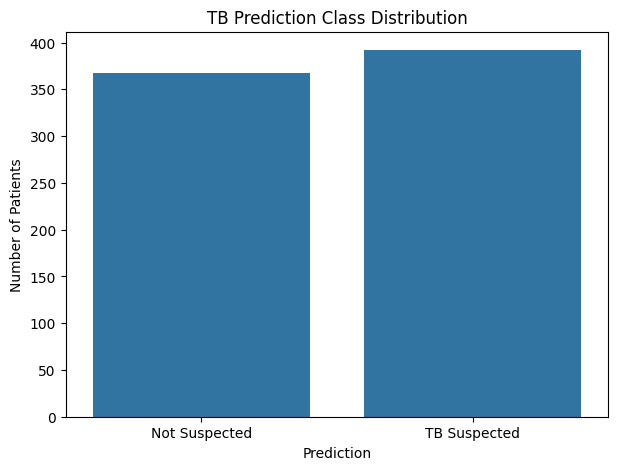

In [15]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Prediction"
)

plt.title("TB Prediction Class Distribution")
plt.xlabel("Prediction")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

Dataset shape: (999, 18)

Columns:
['Patient ID', 'Cough', 'Cough Duration', 'Cough Type', 'Mucus', 'Chest Pain', 'Breathe State', 'Body Temperature', 'Chills', 'Pulmonary Effusion', 'ESR Value', 'Diet', 'Physique', 'Energy Adequacy', 'Smoking', 'Crowding', 'Exposed', 'Prediction']


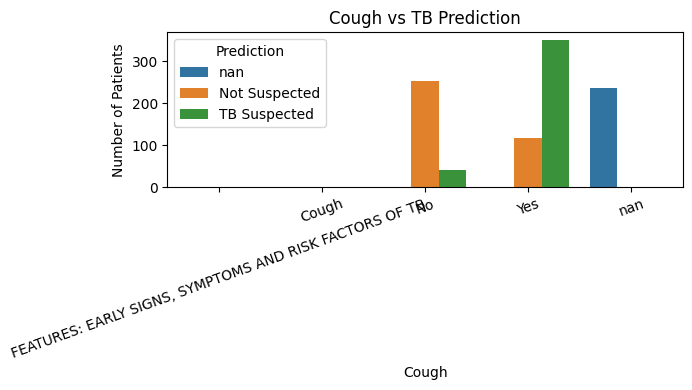

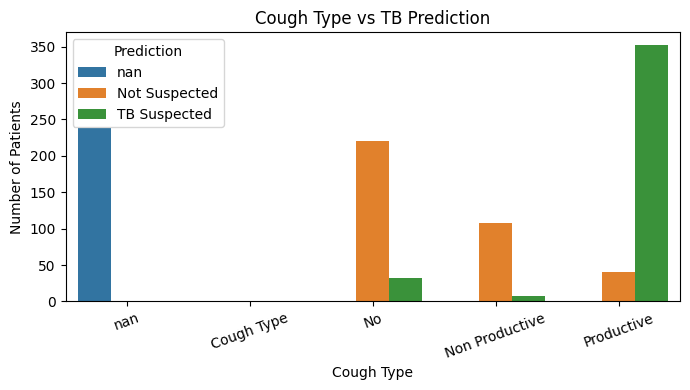

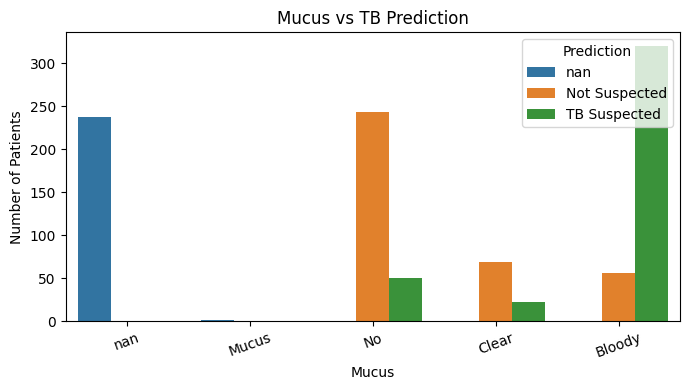

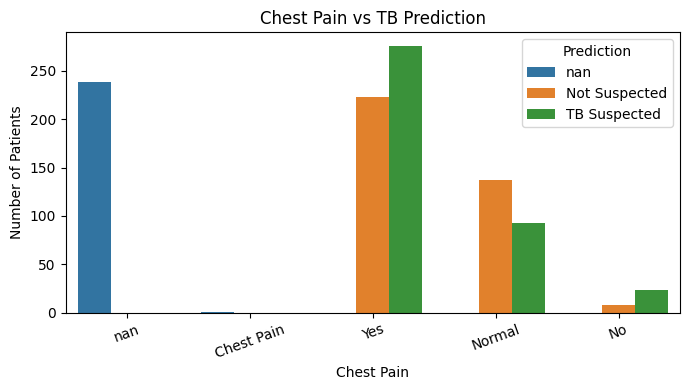

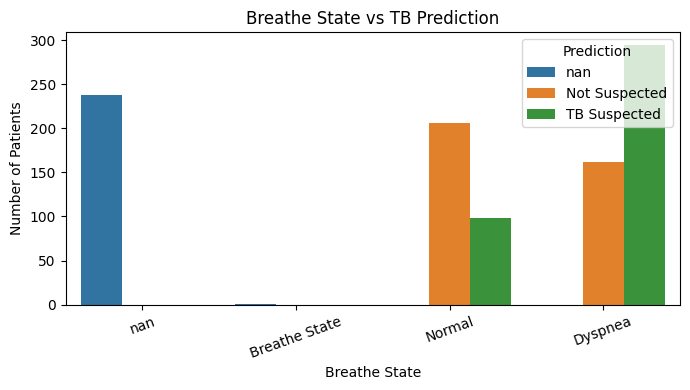

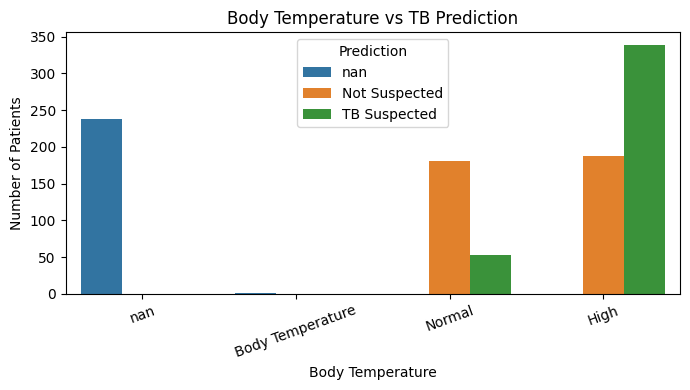

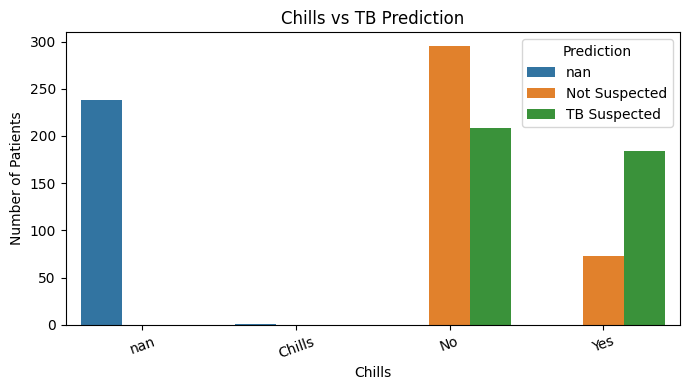

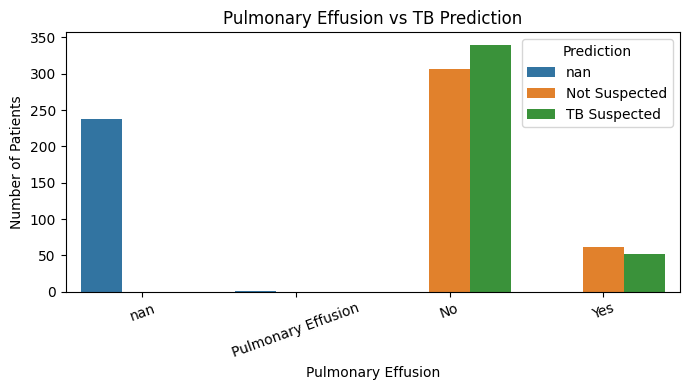

In [16]:
# Cell 14: Clinical Features vs TB Prediction

# ---------------------------------------------------
# STEP 1: Clean column names
# ---------------------------------------------------

df.columns = (
    df.columns
    .astype(str)
    .str.strip()
)

# ---------------------------------------------------
# STEP 2: If the original dataset column names are
# not already correct, rename the first 18 columns
# according to the dataset structure
# ---------------------------------------------------

expected_columns = [
    "Patient ID",
    "Cough",
    "Cough Duration",
    "Cough Type",
    "Mucus",
    "Chest Pain",
    "Breathe State",
    "Body Temperature",
    "Chills",
    "Pulmonary Effusion",
    "ESR Value",
    "Diet",
    "Physique",
    "Energy Adequacy",
    "Smoking",
    "Crowding",
    "Exposed",
    "Prediction"
]

# Remove empty formatting columns if they exist
df = df.iloc[:, :18].copy()

# Rename columns
df.columns = expected_columns

# Clean text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()

# Convert cough duration to numeric
df["Cough Duration"] = pd.to_numeric(
    df["Cough Duration"],
    errors="coerce"
)

# ---------------------------------------------------
# STEP 3: Display columns to verify
# ---------------------------------------------------

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ---------------------------------------------------
# STEP 4: Plot clinical features
# ---------------------------------------------------

categorical_features = [
    "Cough",
    "Cough Type",
    "Mucus",
    "Chest Pain",
    "Breathe State",
    "Body Temperature",
    "Chills",
    "Pulmonary Effusion"
]

for feature in categorical_features:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=feature,
        hue="Prediction"
    )

    plt.title(f"{feature} vs TB Prediction")
    plt.xlabel(feature)
    plt.ylabel("Number of Patients")
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

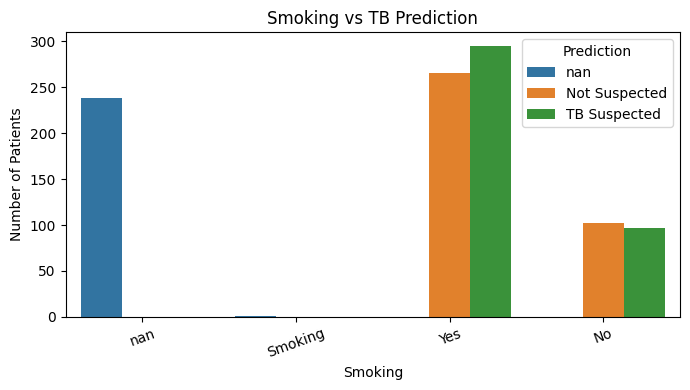

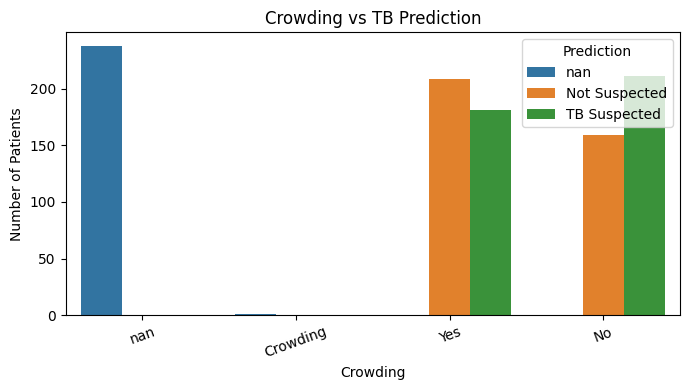

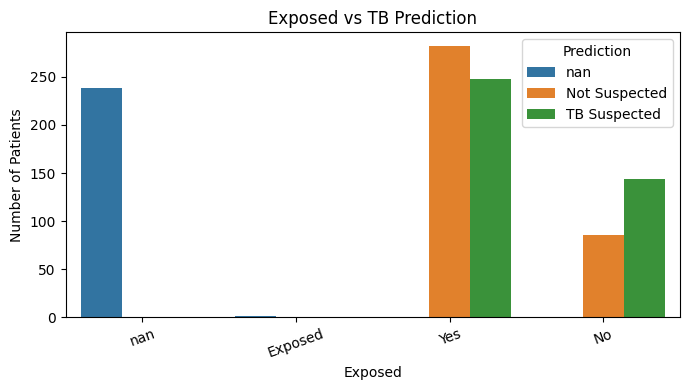

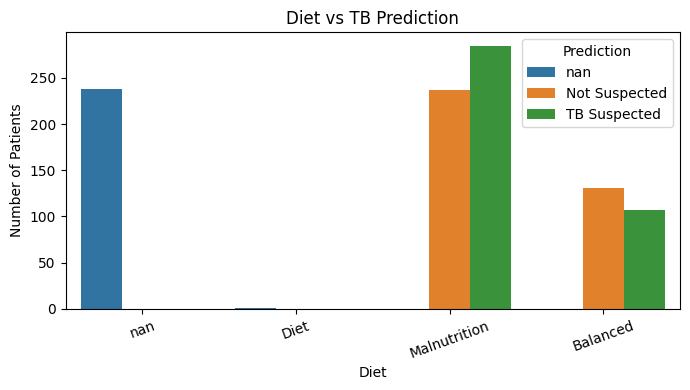

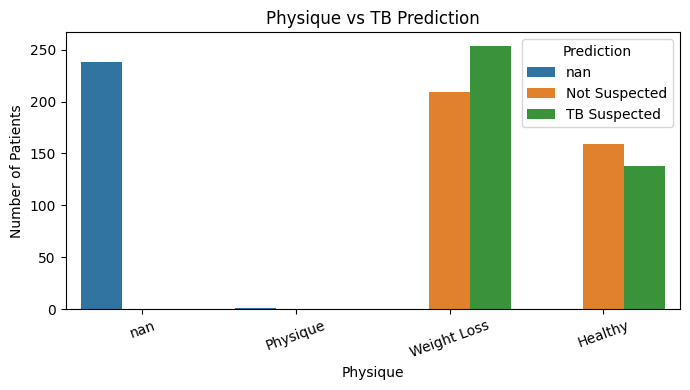

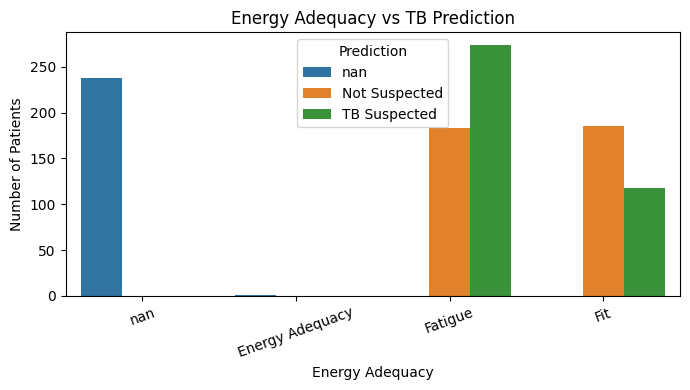

In [17]:
# Cell 15: Lifestyle and Environmental Risk Factors

risk_features = [
    "Smoking",
    "Crowding",
    "Exposed",
    "Diet",
    "Physique",
    "Energy Adequacy"
]

for feature in risk_features:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=feature,
        hue="Prediction"
    )

    plt.title(f"{feature} vs TB Prediction")
    plt.xlabel(feature)
    plt.ylabel("Number of Patients")
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

In [18]:
# Cell 16: Separate Features and Target

# Remove Patient ID because it is only an identifier
X = df.drop(columns=["Patient ID", "Prediction"]).copy()

# Target variable
y = df["Prediction"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

Features shape: (999, 16)
Target shape: (999,)

Feature columns:
['Cough', 'Cough Duration', 'Cough Type', 'Mucus', 'Chest Pain', 'Breathe State', 'Body Temperature', 'Chills', 'Pulmonary Effusion', 'ESR Value', 'Diet', 'Physique', 'Energy Adequacy', 'Smoking', 'Crowding', 'Exposed']

Target classes:
Prediction
TB Suspected     392
Not Suspected    368
nan              239
Name: count, dtype: int64


In [19]:
# Cell 17: Clean and Encode Target Variable

# Remove rows where Patient ID or Prediction is missing
df = df.dropna(
    subset=["Patient ID", "Prediction"]
).copy()

# Clean text values
df["Prediction"] = (
    df["Prediction"]
    .astype(str)
    .str.strip()
)

# Recreate X after removing blank rows
X = df.drop(
    columns=["Patient ID", "Prediction"]
).copy()

# Create target variable
y = df["Prediction"].map({
    "Not Suspected": 0,
    "TB Suspected": 1
})

# Check for unexpected values
print("Target values:")
print(df["Prediction"].value_counts())

print("\nMissing target values:", y.isna().sum())

# Remove any remaining invalid target rows
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

print("\nFinal dataset shape:")
print("X:", X.shape)
print("y:", y.shape)

print("\nFinal target distribution:")
print(y.value_counts())

print("\nTarget encoding:")
print("0 = Not Suspected")
print("1 = TB Suspected")

Target values:
Prediction
TB Suspected     392
Not Suspected    368
Name: count, dtype: int64

Missing target values: 0

Final dataset shape:
X: (760, 16)
y: (760,)

Final target distribution:
Prediction
1    392
0    368
Name: count, dtype: int64

Target encoding:
0 = Not Suspected
1 = TB Suspected


In [20]:
# Cell 18: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTrain-test split completed successfully!")

Training data shape: (532, 16)
Testing data shape: (228, 16)

Training target distribution:
Prediction
1    274
0    258
Name: count, dtype: int64

Testing target distribution:
Prediction
1    118
0    110
Name: count, dtype: int64

Train-test split completed successfully!


In [21]:
# Cell 19: Data Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Convert Cough Duration to numeric
X_train["Cough Duration"] = pd.to_numeric(
    X_train["Cough Duration"],
    errors="coerce"
)

X_test["Cough Duration"] = pd.to_numeric(
    X_test["Cough Duration"],
    errors="coerce"
)

# Numeric feature
numeric_features = [
    "Cough Duration"
]

# Categorical features
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Preprocessing pipeline created successfully.

Numeric features:
['Cough Duration']

Categorical features:
['Cough', 'Cough Type', 'Mucus', 'Chest Pain', 'Breathe State', 'Body Temperature', 'Chills', 'Pulmonary Effusion', 'ESR Value', 'Diet', 'Physique', 'Energy Adequacy', 'Smoking', 'Crowding', 'Exposed']


In [22]:
# Cell 20: Apply Preprocessing

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Original training shape: (532, 16)
Original testing shape: (228, 16)

Processed training shape: (532, 34)
Processed testing shape: (228, 34)

Preprocessing completed successfully!


In [23]:
# Cell 21: Import Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

print("All models imported successfully!")

All models imported successfully!


In [24]:
# Cell 22: Define Machine Learning Models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    ),

    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(32, 16),
        max_iter=1000,
        early_stopping=True,
        random_state=42
    )
}

print("Models created:")
for model_name in models:
    print("-", model_name)

Models created:
- Logistic Regression
- Decision Tree
- Random Forest
- Gaussian Naive Bayes
- AdaBoost
- XGBoost
- Neural Network


In [25]:
# Cell 23: Train and Evaluate All Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train_processed, y_train)

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Probability for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_prob = model.decision_function(X_test_processed)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# Create results table
results_df = pd.DataFrame(results)

# Sort by Recall because this is a TB screening problem
results_df = results_df.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

print("Model evaluation completed!")

display(results_df.round(4))

Model evaluation completed!


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9474,0.9274,0.9746,0.9504,0.9865
1,Logistic Regression,0.9035,0.8810,0.9407,0.9098,0.9483
2,Decision Tree,0.9167,0.9024,0.9407,0.9212,0.9617
3,XGBoost,0.9254,0.9174,0.9407,0.9289,0.9654
4,AdaBoost,0.9254,0.9244,0.9322,0.9283,0.9591
5,Gaussian Naive Bayes,0.8947,0.8917,0.9068,0.8992,0.9450
6,Neural Network,0.8465,0.8374,0.8729,0.8548,0.8966


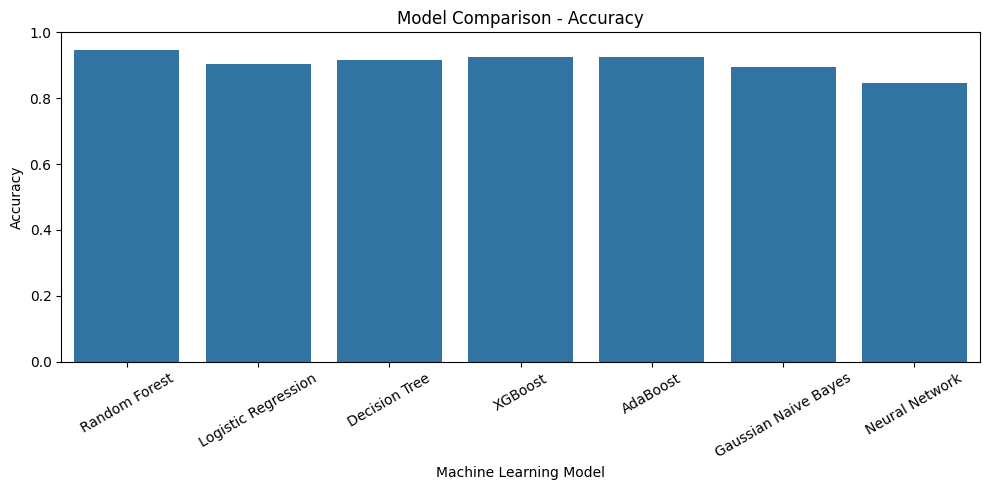

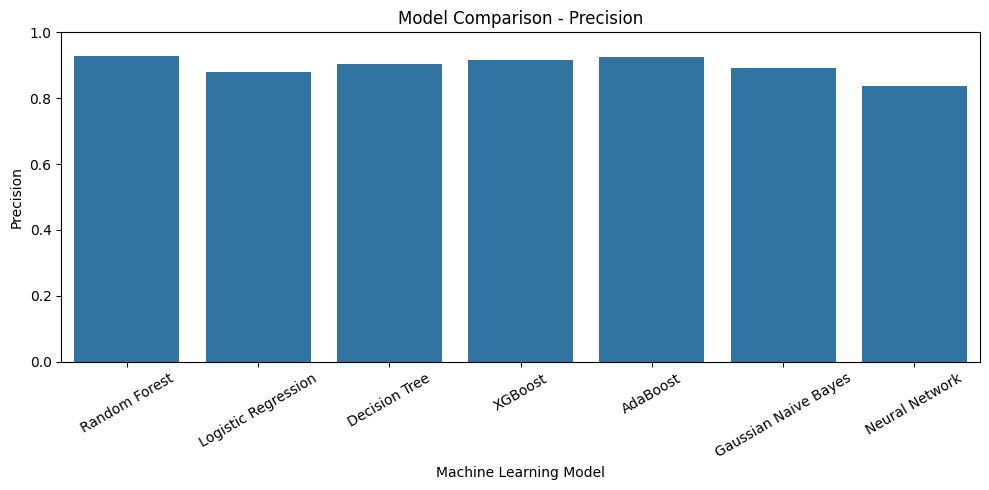

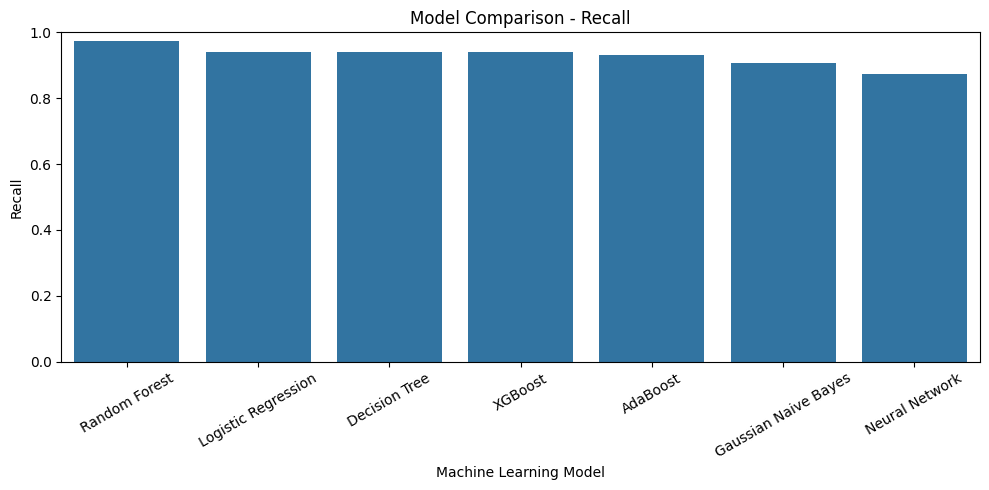

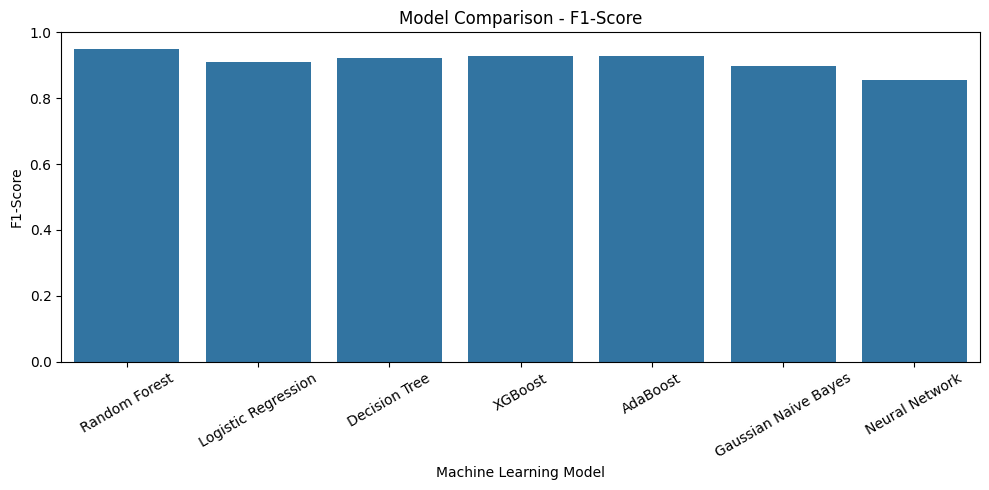

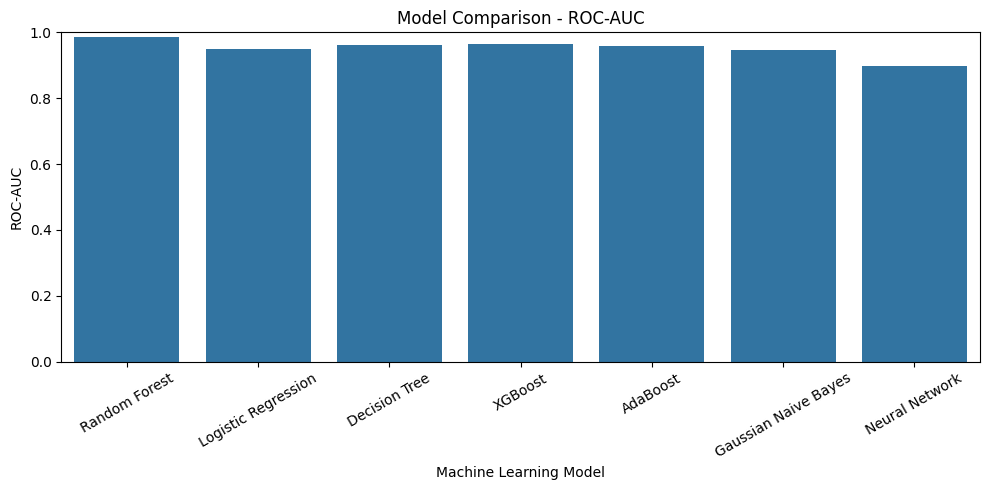

In [26]:
# Cell 24: Model Performance Comparison

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Machine Learning Model")
    plt.ylabel(metric)
    plt.xticks(rotation=30)
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()

In [27]:
# Cell 25: Select Best Model

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best Model:", best_model_name)

print("\nBest Model Performance:")

best_results = results_df[
    results_df["Model"] == best_model_name
]

display(best_results.round(4))

Best Model: Random Forest

Best Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9474,0.9274,0.9746,0.9504,0.9865


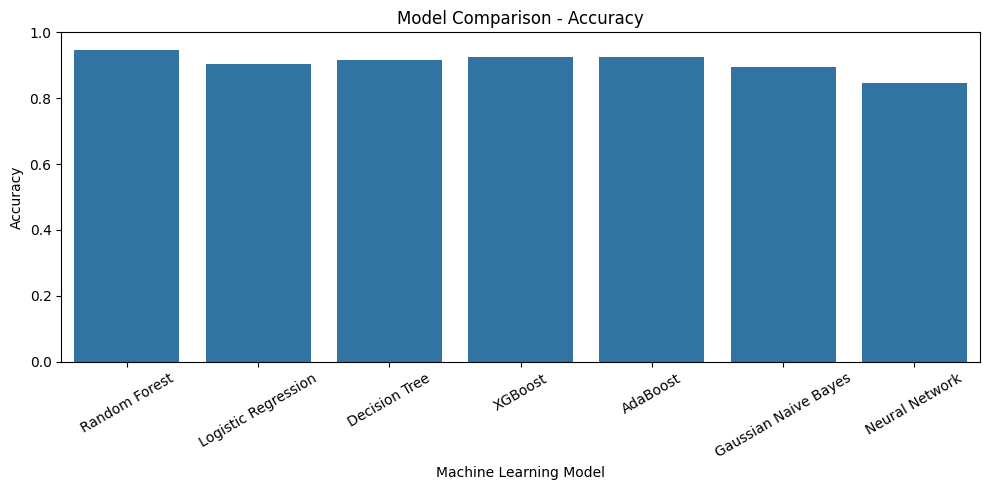

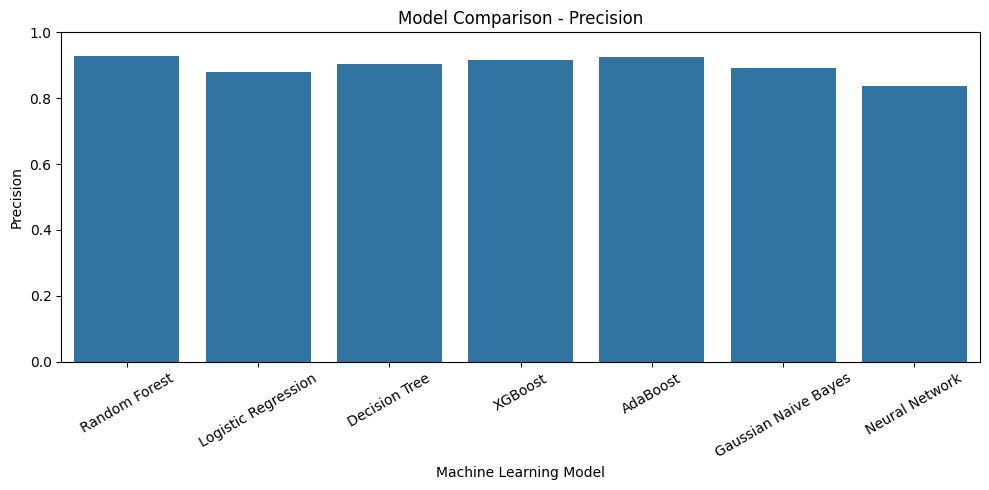

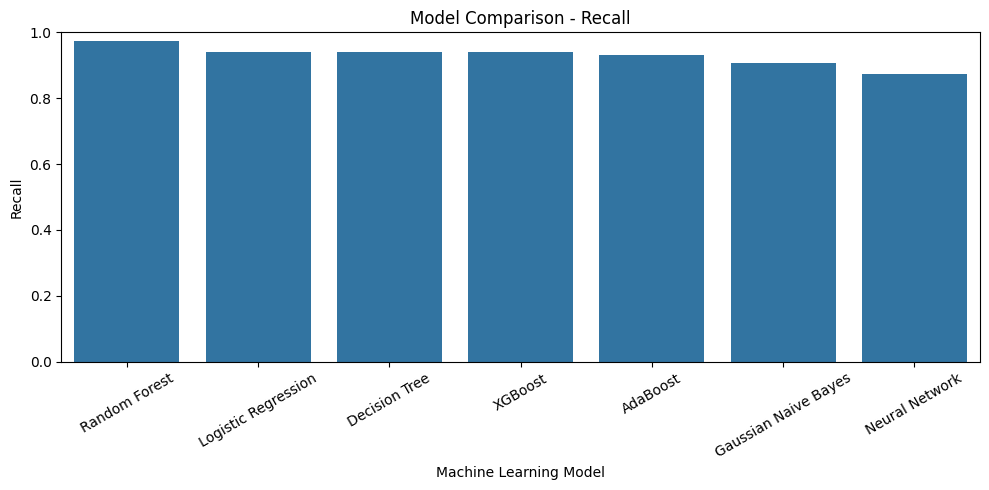

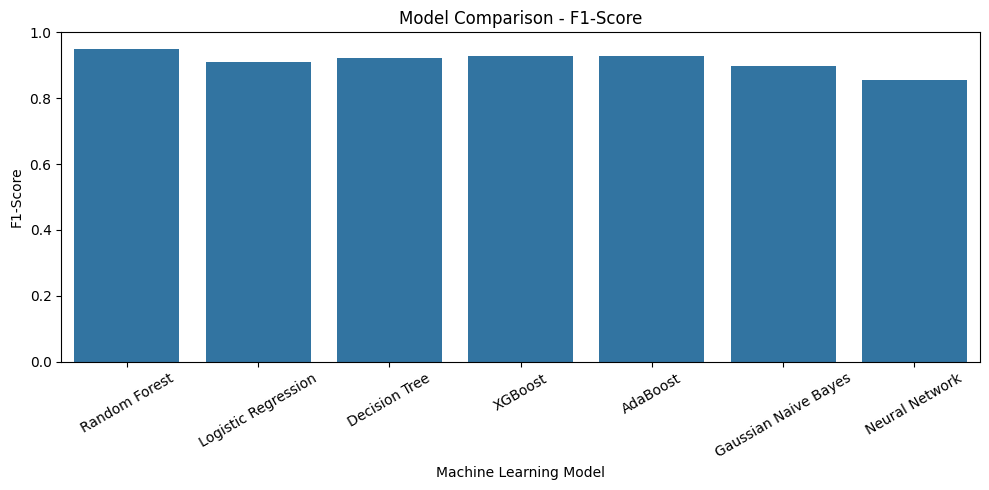

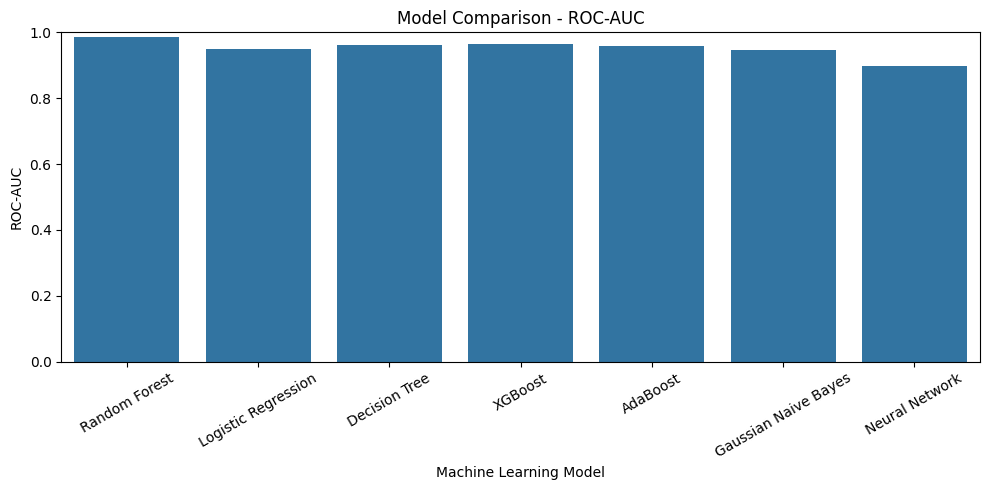

In [28]:
# Cell 24: Model Performance Comparison

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Machine Learning Model")
    plt.ylabel(metric)
    plt.xticks(rotation=30)
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()

In [29]:
# Cell 25: Select Best Model

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best Model:", best_model_name)

print("\nBest Model Performance:")

best_results = results_df[
    results_df["Model"] == best_model_name
]

display(best_results.round(4))

Best Model: Random Forest

Best Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9474,0.9274,0.9746,0.9504,0.9865


Confusion Matrix:
[[101   9]
 [  3 115]]


<Figure size 700x600 with 0 Axes>

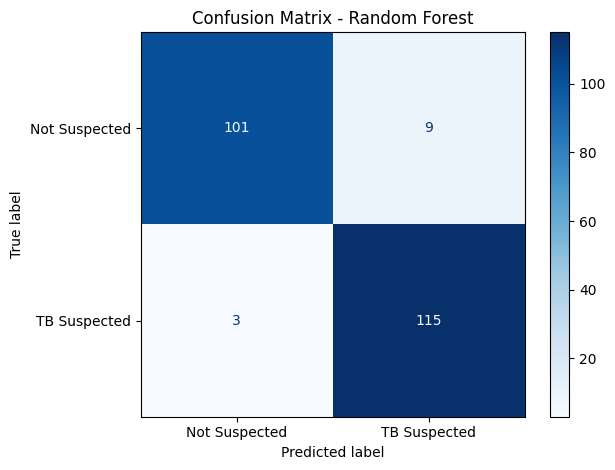

In [30]:
# Cell 26: Confusion Matrix for Best Model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_best = best_model.predict(X_test_processed)

cm = confusion_matrix(y_test, y_pred_best)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Suspected", "TB Suspected"]
)

plt.figure(figsize=(7, 6))
disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

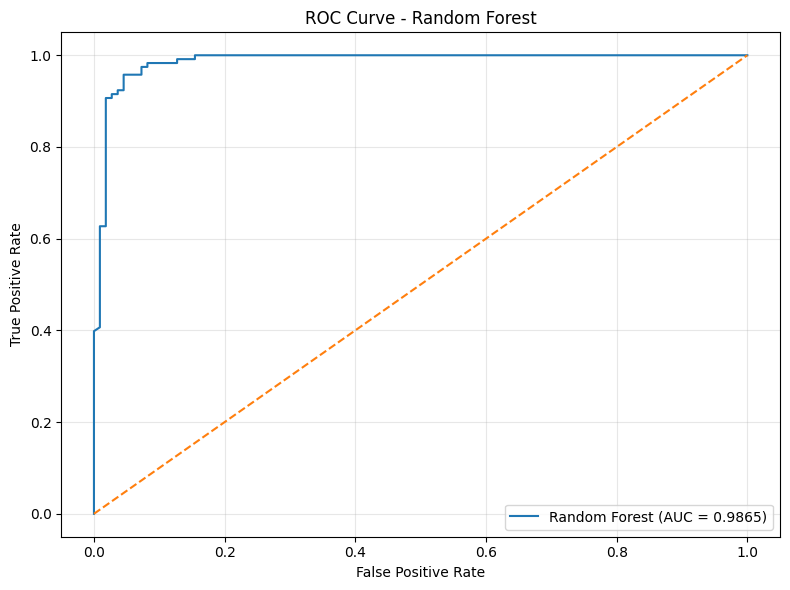

ROC-AUC Score: 0.9865


In [31]:
# Cell 27: ROC Curve for Best Model

from sklearn.metrics import roc_curve, auc

y_prob_best = best_model.predict_proba(
    X_test_processed
)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_best
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

In [32]:
# Cell 28: Feature Importance

# Get feature names after One-Hot Encoding

feature_names = preprocessor.get_feature_names_out()

# Get importance values
importance_values = best_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Important Features:")

display(
    feature_importance_df.head(15).round(4)
)

Top 15 Important Features:


,Feature,Importance
0,categorical__Cough Type_Productive,0.1865
1,numeric__Cough Duration,0.1478
2,categorical__Mucus_Bloody,0.1063
3,categorical__ESR Value_Disturbed,0.0515
4,categorical__Cough_No,0.0427
5,categorical__ESR Value_Normal,0.0426
6,categorical__Cough Type_No,0.0425
7,categorical__Cough_Yes,0.0396
8,categorical__Cough Type_Non Productive,0.0332
9,categorical__Mucus_No,0.0280


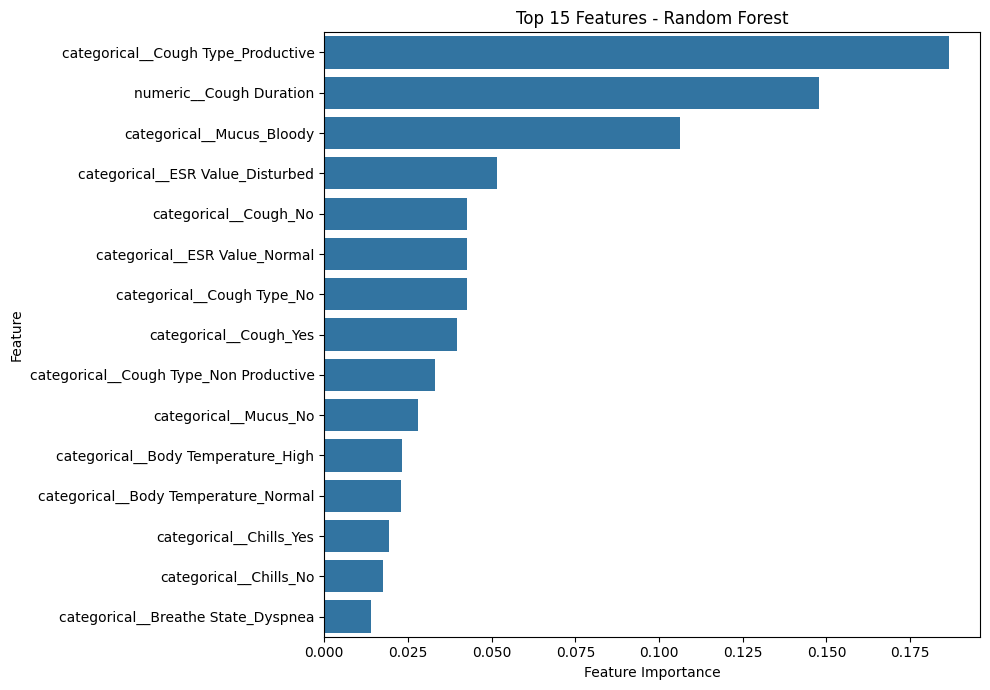

In [33]:
# Cell 29: Top 15 Feature Importance

top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [34]:
# Cell 30: Final Model Summary

print("=" * 60)
print("FINAL MODEL SUMMARY")
print("=" * 60)

print(f"\nSelected Model: {best_model_name}")

print(f"Accuracy  : {best_results['Accuracy'].iloc[0] * 100:.2f}%")
print(f"Precision : {best_results['Precision'].iloc[0] * 100:.2f}%")
print(f"Recall    : {best_results['Recall'].iloc[0] * 100:.2f}%")
print(f"F1-Score  : {best_results['F1-Score'].iloc[0] * 100:.2f}%")
print(f"ROC-AUC   : {best_results['ROC-AUC'].iloc[0]:.4f}")

print("\nInterpretation:")
print(
    "The Random Forest model demonstrated strong predictive "
    "performance on the test dataset. Its high recall is "
    "particularly relevant for early TB screening support, "
    "where identifying potentially suspected cases is important."
)

print(
    "\nThis model is intended as a screening decision-support "
    "tool and should not be considered a replacement for "
    "clinical diagnosis."
)

FINAL MODEL SUMMARY

Selected Model: Random Forest
Accuracy  : 94.74%
Precision : 92.74%
Recall    : 97.46%
F1-Score  : 95.04%
ROC-AUC   : 0.9865

Interpretation:
The Random Forest model demonstrated strong predictive performance on the test dataset. Its high recall is particularly relevant for early TB screening support, where identifying potentially suspected cases is important.

This model is intended as a screening decision-support tool and should not be considered a replacement for clinical diagnosis.


In [35]:
# Cell 31: TB Risk Prediction Function

def predict_tb_risk(patient_data):

    # Convert input into DataFrame
    patient_df = pd.DataFrame([patient_data])

    # Convert cough duration to numeric
    patient_df["Cough Duration"] = pd.to_numeric(
        patient_df["Cough Duration"],
        errors="coerce"
    )

    # Apply the same preprocessing used during training
    patient_processed = preprocessor.transform(patient_df)

    # Make prediction
    prediction = best_model.predict(patient_processed)[0]

    # Get probability
    probability = best_model.predict_proba(
        patient_processed
    )[0][1]

    if prediction == 1:
        result = "TB Suspected"
    else:
        result = "Not Suspected"

    return result, probability

In [36]:
# Cell 32: Test Prediction

sample_patient = {
    "Cough": "Yes",
    "Cough Duration": 2.5,
    "Cough Type": "Productive",
    "Mucus": "Bloody",
    "Chest Pain": "Yes",
    "Breathe State": "Dyspnea",
    "Body Temperature": "High",
    "Chills": "Yes",
    "Pulmonary Effusion": "Yes",
    "ESR Value": "Disturbed",
    "Diet": "Malnutrition",
    "Physique": "Weight Loss",
    "Energy Adequacy": "Fatigue",
    "Smoking": "Yes",
    "Crowding": "Yes",
    "Exposed": "Yes"
}

prediction, probability = predict_tb_risk(sample_patient)

print("TB Screening Prediction")
print("-" * 35)
print("Prediction:", prediction)
print(f"TB Probability: {probability * 100:.2f}%")

TB Screening Prediction
-----------------------------------
Prediction: TB Suspected
TB Probability: 99.83%


In [37]:
# Cell 33: Save Trained Model

import joblib

joblib.dump(
    best_model,
    "tb_random_forest_model.pkl"
)

joblib.dump(
    preprocessor,
    "tb_preprocessor.pkl"
)

print("Model saved as: tb_random_forest_model.pkl")
print("Preprocessor saved as: tb_preprocessor.pkl")

Model saved as: tb_random_forest_model.pkl
Preprocessor saved as: tb_preprocessor.pkl


In [38]:
# Cell 34: Save Model Comparison Results

results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

feature_importance_df.to_csv(
    "feature_importance_results.csv",
    index=False
)

print("Model comparison results saved.")
print("Feature importance results saved.")

Model comparison results saved.
Feature importance results saved.


In [39]:
# Cell 35: Save Clean Dataset

df.to_csv(
    "TB_cleaned_dataset.csv",
    index=False
)

print("Cleaned dataset saved as TB_cleaned_dataset.csv")

Cleaned dataset saved as TB_cleaned_dataset.csv


In [40]:
!pip install -q gradio

In [41]:
# Cell 36: TB Risk Prediction Dashboard

import gradio as gr
import pandas as pd

def predict_tb_dashboard(
    cough,
    cough_duration,
    cough_type,
    mucus,
    chest_pain,
    breathe_state,
    body_temperature,
    chills,
    pulmonary_effusion,
    esr_value,
    diet,
    physique,
    energy_adequacy,
    smoking,
    crowding,
    exposed
):

    # Create patient data
    patient_data = {
        "Cough": cough,
        "Cough Duration": cough_duration,
        "Cough Type": cough_type,
        "Mucus": mucus,
        "Chest Pain": chest_pain,
        "Breathe State": breathe_state,
        "Body Temperature": body_temperature,
        "Chills": chills,
        "Pulmonary Effusion": pulmonary_effusion,
        "ESR Value": esr_value,
        "Diet": diet,
        "Physique": physique,
        "Energy Adequacy": energy_adequacy,
        "Smoking": smoking,
        "Crowding": crowding,
        "Exposed": exposed
    }

    # Convert to DataFrame
    patient_df = pd.DataFrame([patient_data])

    # Convert cough duration
    patient_df["Cough Duration"] = pd.to_numeric(
        patient_df["Cough Duration"],
        errors="coerce"
    )

    # Apply same preprocessing
    patient_processed = preprocessor.transform(patient_df)

    # Prediction
    prediction = best_model.predict(
        patient_processed
    )[0]

    # Probability
    probability = best_model.predict_proba(
        patient_processed
    )[0][1]

    probability_percent = probability * 100

    # Result
    if prediction == 1:
        result = "⚠️ TB Suspected"
        recommendation = (
            "The model identifies this case as TB Suspected. "
            "Further clinical evaluation is recommended."
        )
    else:
        result = "✅ TB Not Suspected"
        recommendation = (
            "The model identifies this case as Not Suspected. "
            "Clinical assessment should still be considered "
            "when symptoms or risk factors are present."
        )

    return (
        result,
        f"{probability_percent:.2f}%",
        recommendation
    )

In [42]:
# ============================================================
# CELL 36 — XAI
# ============================================================

!pip install -q shap openai

import shap
import numpy as np
import pandas as pd
from openai import OpenAI

print("SHAP and OpenAI libraries installed successfully.")

SHAP and OpenAI libraries installed successfully.


In [43]:
# ============================================================
# CELL 36.1 — SHAP EXPLAINABLE AI
# ============================================================

# Create SHAP TreeExplainer for the trained Random Forest
shap_explainer = shap.TreeExplainer(best_model)

# Get transformed feature names
shap_feature_names = preprocessor.get_feature_names_out()

print("SHAP explainer created successfully.")
print("Number of transformed features:", len(shap_feature_names))

SHAP explainer created successfully.
Number of transformed features: 34


In [44]:
# ============================================================
# CELL 36.2 — TEST SHAP EXPLANATION
# ============================================================

# Transform the test data using the existing preprocessor
X_test_processed = preprocessor.transform(X_test)

# Convert to numpy array if necessary
X_test_processed = np.asarray(X_test_processed)

# Take one test patient
sample = X_test_processed[0:1]

# Generate SHAP values
shap_values = shap_explainer.shap_values(sample)

print("SHAP values generated successfully!")

# Check the SHAP output shape
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Shape of class SHAP values:", np.array(shap_values[0]).shape)
else:
    print("SHAP output shape:", np.array(shap_values).shape)

SHAP values generated successfully!
SHAP output type: <class 'numpy.ndarray'>
SHAP output shape: (1, 34, 2)


In [45]:
# ============================================================
# CELL 36.3 — PATIENT-LEVEL SHAP EXPLANATION
# ============================================================

def get_shap_explanation(patient_processed):

    shap_values = shap_explainer.shap_values(patient_processed)

    # Handle different SHAP output formats
    if isinstance(shap_values, list):

        values = np.array(shap_values[-1])

        if values.ndim == 2:
            values = values[0]

    else:

        values = np.array(shap_values)

        if values.ndim == 3:
            # Select TB Suspected class
            values = values[0, :, -1]

        elif values.ndim == 2:
            values = values[0]

        else:
            values = values.flatten()

    # Get feature names
    feature_names = list(shap_feature_names)

    # Make sure lengths match
    n = min(len(values), len(feature_names))

    explanation_df = pd.DataFrame({
        "Feature": feature_names[:n],
        "SHAP Value": values[:n]
    })

    # Absolute contribution
    explanation_df["Absolute SHAP"] = (
        explanation_df["SHAP Value"].abs()
    )

    # Sort by strongest influence
    explanation_df = explanation_df.sort_values(
        "Absolute SHAP",
        ascending=False
    ).reset_index(drop=True)

    return explanation_df

In [46]:
# ============================================================
# CELL 36.4 — DISPLAY TOP SHAP FACTORS
# ============================================================

sample_shap = get_shap_explanation(X_test_processed[0:1])

print("Top 10 factors influencing the prediction:")
display(sample_shap.head(10))

Top 10 factors influencing the prediction:


,Feature,SHAP Value,Absolute SHAP
0,categorical__Cough Type_Productive,-0.178566,0.178566
1,numeric__Cough Duration,0.099857,0.099857
2,categorical__Cough Type_No,-0.075752,0.075752
3,categorical__Mucus_Bloody,0.071033,0.071033
4,categorical__ESR Value_Disturbed,0.040682,0.040682
5,categorical__ESR Value_Normal,0.031603,0.031603
6,categorical__Chest Pain_Normal,-0.025095,0.025095
7,categorical__Chills_Yes,0.022718,0.022718
8,categorical__Cough_No,0.022587,0.022587
9,categorical__Cough Type_Non Productive,0.020697,0.020697


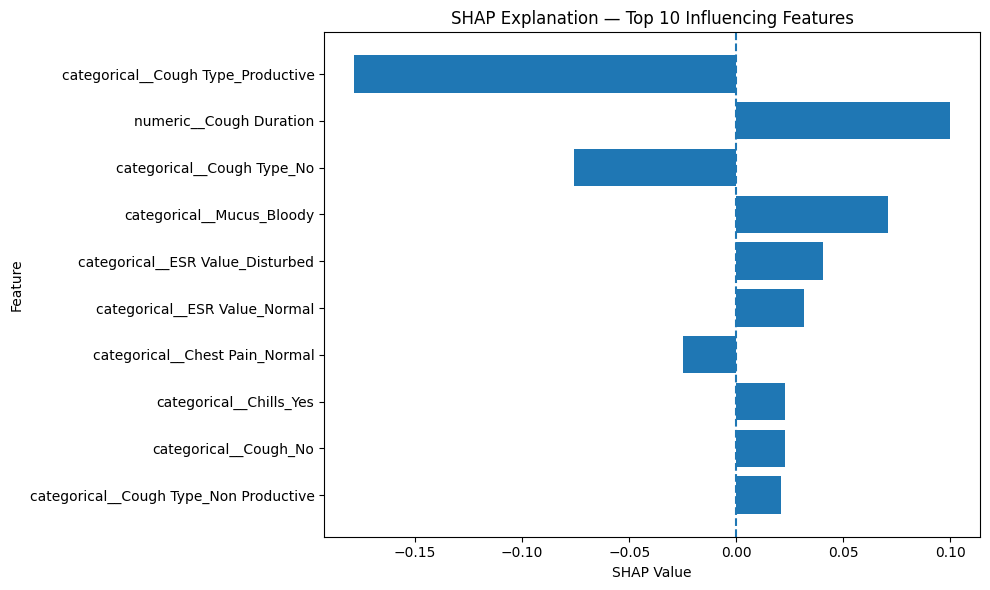

In [47]:
# ============================================================
# CELL 36.5 — SHAP VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# Get SHAP values for the selected test patient
sample = X_test_processed[0:1]

shap_values_raw = shap_explainer.shap_values(sample)

# Handle SHAP output format
if isinstance(shap_values_raw, list):
    values = np.array(shap_values_raw[-1])[0]
else:
    values_array = np.array(shap_values_raw)

    if values_array.ndim == 3:
        values = values_array[0, :, -1]
    elif values_array.ndim == 2:
        values = values_array[0]
    else:
        values = values_array.flatten()

# Create dataframe
shap_plot_df = pd.DataFrame({
    "Feature": shap_feature_names,
    "SHAP Value": values
})

# Select strongest 10 factors
shap_plot_df["Absolute SHAP"] = shap_plot_df["SHAP Value"].abs()

shap_plot_df = shap_plot_df.sort_values(
    "Absolute SHAP",
    ascending=True
).tail(10)

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    shap_plot_df["Feature"],
    shap_plot_df["SHAP Value"]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Explanation — Top 10 Influencing Features")

plt.tight_layout()
plt.show()

In [48]:
# ============================================================
# CELL 36.6 — CLEAN SHAP FEATURE NAMES
# ============================================================

def clean_shap_feature_name(feature):

    feature = str(feature)

    feature = feature.replace("categorical__", "")
    feature = feature.replace("numeric__", "")
    feature = feature.replace("cat__", "")
    feature = feature.replace("num__", "")

    feature = feature.replace("_", " ")

    return feature


sample_shap["Readable Feature"] = (
    sample_shap["Feature"]
    .apply(clean_shap_feature_name)
)

display(
    sample_shap[
        ["Readable Feature", "SHAP Value", "Absolute SHAP"]
    ].head(10)
)

,Readable Feature,SHAP Value,Absolute SHAP
0,Cough Type Productive,-0.178566,0.178566
1,Cough Duration,0.099857,0.099857
2,Cough Type No,-0.075752,0.075752
3,Mucus Bloody,0.071033,0.071033
4,ESR Value Disturbed,0.040682,0.040682
5,ESR Value Normal,0.031603,0.031603
6,Chest Pain Normal,-0.025095,0.025095
7,Chills Yes,0.022718,0.022718
8,Cough No,0.022587,0.022587
9,Cough Type Non Productive,0.020697,0.020697


In [49]:
# ============================================================
# CELL 36.7 — CLINICAL ACTION GUIDANCE
# ============================================================

def get_clinical_action(prediction, probability):

    if prediction == 1:

        return """
### Clinical Action Guidance

**Model Result: TB Suspected**

The model indicates a higher predicted TB risk based on
the provided clinical and demographic features.

Recommended next step:

- Seek assessment from a qualified healthcare professional.
- Consider appropriate confirmatory TB evaluation and testing.
- The model output should be used for early screening support,
  not as a standalone diagnosis.

"""

    else:

        return """
### Clinical Action Guidance

**Model Result: TB Not Suspected**

The model indicates a lower predicted TB risk based on
the provided clinical and demographic features.

Recommended next step:

- A low model risk does not completely rule out tuberculosis.
- If symptoms persist or clinical concern remains, consult
  a qualified healthcare professional.
- Further evaluation should be based on clinical judgment.

"""

print("Clinical Action Guidance function created successfully.")

Clinical Action Guidance function created successfully.


In [50]:
# ============================================================
# CELL 36.8 — TEST CLINICAL GUIDANCE
# ============================================================

test_prediction = 1
test_probability = 0.82

print(
    get_clinical_action(
        test_prediction,
        test_probability
    )
)


### Clinical Action Guidance

**Model Result: TB Suspected**

The model indicates a higher predicted TB risk based on
the provided clinical and demographic features.

Recommended next step:

- Seek assessment from a qualified healthcare professional.
- Consider appropriate confirmatory TB evaluation and testing.
- The model output should be used for early screening support,
  not as a standalone diagnosis.




In [56]:
# ============================================================
# CELL 37 — FINAL TB RISK PREDICTION DASHBOARD
# Random Forest + SHAP Explainable AI
# ============================================================

import gradio as gr
import pandas as pd
import numpy as np
import shap
import html


# ============================================================
# 1. SHAP EXPLAINER
# ============================================================

try:
    shap_explainer
except NameError:
    shap_explainer = shap.TreeExplainer(best_model)

try:
    shap_feature_names
except NameError:
    shap_feature_names = preprocessor.get_feature_names_out()


# ============================================================
# 2. FEATURE NAMES
# ============================================================

FEATURE_COLUMNS = [
    "Cough",
    "Cough Duration",
    "Cough Type",
    "Mucus",
    "Chest Pain",
    "Breathe State",
    "Body Temperature",
    "Chills",
    "Pulmonary Effusion",
    "ESR Value",
    "Diet",
    "Physique",
    "Energy Adequacy",
    "Smoking",
    "Crowding",
    "Exposed"
]


# ============================================================
# 3. SHAP FUNCTION
# ============================================================

def get_patient_shap(patient_processed):

    try:

        shap_values = shap_explainer.shap_values(
            patient_processed
        )

        # -----------------------------------------------
        # Handle different SHAP output formats
        # -----------------------------------------------

        if isinstance(shap_values, list):

            if len(shap_values) > 1:
                values = np.asarray(
                    shap_values[1]
                )[0]
            else:
                values = np.asarray(
                    shap_values[0]
                )[0]

        else:

            values = np.asarray(
                shap_values
            )

            if values.ndim == 3:
                values = values[0, :, 1]

            elif values.ndim == 2:
                values = values[0]

            else:
                values = values.flatten()

        values = np.asarray(
            values
        ).flatten()

        # -----------------------------------------------
        # Safety check
        # -----------------------------------------------

        if len(values) != len(shap_feature_names):

            raw = np.asarray(shap_values)

            if raw.ndim == 3:
                values = raw[0, :, 1]

            elif raw.ndim == 2:
                values = raw[0]

            else:
                values = raw.flatten()

        # -----------------------------------------------
        # Create dataframe
        # -----------------------------------------------

        shap_df = pd.DataFrame({

            "Feature":
                shap_feature_names,

            "SHAP Value":
                values

        })

        shap_df["Absolute SHAP"] = (
            shap_df["SHAP Value"].abs()
        )

        shap_df = shap_df.sort_values(
            "Absolute SHAP",
            ascending=False
        ).head(5)

        return shap_df

    except Exception as e:

        print(
            "SHAP Error:",
            e
        )

        return pd.DataFrame({

            "Feature": [
                "SHAP explanation unavailable"
            ],

            "SHAP Value": [
                0
            ],

            "Absolute SHAP": [
                0
            ]

        })


# ============================================================
# 4. CLEAN SHAP FEATURE NAME
# ============================================================

def clean_feature_name(name):

    name = str(name)

    name = name.replace(
        "numeric__",
        ""
    )

    name = name.replace(
        "categorical__",
        ""
    )

    name = name.replace(
        "_",
        " "
    )

    return name.strip()


# ============================================================
# 5. CLINICAL GUIDANCE
# ============================================================

def get_clinical_guidance(probability):

    if probability >= 0.70:

        level = "HIGH MODEL-ESTIMATED RISK"
        level_class = "high"

        message = """
        The model indicates a high estimated risk for the
        <b>TB Suspected</b> class.
        """

        points = [
            "Further clinical assessment is recommended.",
            "Appropriate diagnostic testing should be considered.",
            "Relevant symptoms and exposure history should be reviewed.",
            "The prediction should be interpreted by a qualified healthcare professional."
        ]

    elif probability >= 0.40:

        level = "MODERATE MODEL-ESTIMATED RISK"
        level_class = "moderate"

        message = """
        The model indicates a moderate estimated risk for the
        <b>TB Suspected</b> class.
        """

        points = [
            "Further clinical assessment may be appropriate.",
            "Relevant symptoms and risk factors should be reviewed.",
            "Diagnostic testing may be considered based on clinical judgement.",
            "This prediction should not be used as a standalone diagnosis."
        ]

    else:

        level = "LOW MODEL-ESTIMATED RISK"
        level_class = "low"

        message = """
        The model indicates a lower estimated risk for the
        <b>TB Suspected</b> class.
        """

        points = [
            "Continue appropriate clinical assessment when indicated.",
            "Consider symptoms and other clinical factors.",
            "A low model score does not completely rule out TB."
        ]

    list_items = ""

    for point in points:

        list_items += f"""
        <li>{point}</li>
        """

    return f"""

    <div class="clinical-guidance-card">

        <div class="guidance-badge {level_class}">
            {level}
        </div>

        <div class="guidance-text">

            <p>
                {message}
            </p>

            <ul>
                {list_items}
            </ul>

        </div>

    </div>

    """


# ============================================================
# 6. PATIENT SUMMARY HTML
# ============================================================

def create_patient_summary(patient_data):

    rows = ""

    for feature in FEATURE_COLUMNS:

        value = patient_data.iloc[0][feature]

        rows += f"""

        <tr>

            <td class="summary-feature">
                {html.escape(str(feature))}
            </td>

            <td class="summary-value">
                {html.escape(str(value))}
            </td>

        </tr>

        """

    return f"""

    <div class="patient-card">

        <table class="patient-table">

            <thead>

                <tr>

                    <th>
                        Clinical / Demographic Feature
                    </th>

                    <th>
                        Patient Value
                    </th>

                </tr>

            </thead>

            <tbody>

                {rows}

            </tbody>

        </table>

    </div>

    """


# ============================================================
# 7. SHAP HTML
# ============================================================

def create_shap_html(shap_df):

    rows = ""

    for _, row in shap_df.iterrows():

        feature = clean_feature_name(
            row["Feature"]
        )

        shap_value = float(
            row["SHAP Value"]
        )

        if shap_value >= 0:

            direction = "Supports TB Suspected"
            direction_class = "positive"
            sign = "+"

        else:

            direction = "Pushes away from TB Suspected"
            direction_class = "negative"
            sign = ""

        rows += f"""

        <tr>

            <td class="shap-feature">
                {html.escape(feature)}
            </td>

            <td class="shap-number {direction_class}">
                {sign}{shap_value:.4f}
            </td>

            <td class="shap-direction">
                {direction}
            </td>

        </tr>

        """

    return f"""

    <div class="shap-card">

        <p class="shap-description">
            SHAP values show which transformed features contributed
            most to this individual prediction.
        </p>

        <table class="shap-table">

            <thead>

                <tr>

                    <th>
                        Feature
                    </th>

                    <th>
                        SHAP Value
                    </th>

                    <th>
                        Interpretation
                    </th>

                </tr>

            </thead>

            <tbody>

                {rows}

            </tbody>

        </table>

    </div>

    """


# ============================================================
# 8. MAIN PREDICTION FUNCTION
# ============================================================

def predict_tb_dashboard(

    cough,
    cough_duration,
    cough_type,
    mucus,
    chest_pain,
    breathe_state,
    body_temperature,
    chills,
    pulmonary_effusion,
    esr_value,
    diet,
    physique,
    energy_adequacy,
    smoking,
    crowding,
    exposed

):

    # --------------------------------------------------------
    # Create patient dataframe
    # --------------------------------------------------------

    patient_data = pd.DataFrame([{

        "Cough":
            cough,

        "Cough Duration":
            float(cough_duration),

        "Cough Type":
            cough_type,

        "Mucus":
            mucus,

        "Chest Pain":
            chest_pain,

        "Breathe State":
            breathe_state,

        "Body Temperature":
            body_temperature,

        "Chills":
            chills,

        "Pulmonary Effusion":
            pulmonary_effusion,

        "ESR Value":
            esr_value,

        "Diet":
            diet,

        "Physique":
            physique,

        "Energy Adequacy":
            energy_adequacy,

        "Smoking":
            smoking,

        "Crowding":
            crowding,

        "Exposed":
            exposed

    }])


    # --------------------------------------------------------
    # Transform data
    # --------------------------------------------------------

    patient_processed = preprocessor.transform(
        patient_data
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    prediction = best_model.predict(
        patient_processed
    )[0]

    probabilities = best_model.predict_proba(
        patient_processed
    )[0]


    # --------------------------------------------------------
    # Safely locate TB Suspected probability
    # --------------------------------------------------------

    try:

        tb_index = list(
            best_model.classes_
        ).index(1)

    except ValueError:

        tb_index = 1


    probability = float(
        probabilities[tb_index]
    )


    # --------------------------------------------------------
    # Prediction label
    # --------------------------------------------------------

    if prediction == 1:

        prediction_label = "TB Suspected"

        prediction_class = (
            "prediction-positive"
        )

    else:

        prediction_label = "TB Not Suspected"

        prediction_class = (
            "prediction-negative"
        )


    # --------------------------------------------------------
    # Risk band
    # --------------------------------------------------------

    if probability >= 0.70:

        risk_band = "HIGH"
        risk_class = "risk-high"

    elif probability >= 0.40:

        risk_band = "MODERATE"
        risk_class = "risk-moderate"

    else:

        risk_band = "LOW"
        risk_class = "risk-low"


    # ========================================================
    # RESULT HTML
    # ========================================================

    result_html = f"""

    <div class="final-result-card">

        <div class="result-small-title">
            SCREENING RESULT
        </div>

        <div class="{prediction_class}">
            {prediction_label}
        </div>

        <div class="probability-title">
            Model-Estimated Probability for TB Suspected
        </div>

        <div class="probability-number">
            {probability * 100:.2f}%
        </div>

        <div class="progress-background">

            <div
                class="progress-fill"
                style="width:{probability * 100:.2f}%;">
            </div>

        </div>

        <div class="{risk_class}">
            {risk_band} RISK
        </div>

        <div class="risk-explanation">

            Risk bands are project-defined demonstration
            thresholds and are not clinically validated
            diagnostic thresholds.

        </div>

    </div>

    """


    # ========================================================
    # SHAP
    # ========================================================

    shap_df = get_patient_shap(
        patient_processed
    )

    shap_html = create_shap_html(
        shap_df
    )


    # ========================================================
    # PATIENT SUMMARY
    # ========================================================

    summary_html = create_patient_summary(
        patient_data
    )


    # ========================================================
    # CLINICAL GUIDANCE
    # ========================================================

    guidance_html = get_clinical_guidance(
        probability
    )


    return (

        result_html,
        summary_html,
        shap_html,
        guidance_html

    )


# ============================================================
# 9. HIGH-RISK DEMO
# ============================================================

def high_risk_demo():

    return (

        "Yes",          # Cough
        3,              # Cough Duration
        "Productive",   # Cough Type
        "Bloody",       # Mucus
        "Yes",          # Chest Pain
        "Dyspnea",      # Breathe State
        "High",         # Body Temperature
        "Yes",          # Chills
        "Yes",          # Pulmonary Effusion
        "Disturbed",    # ESR Value
        "Malnutrition", # Diet
        "Weight Loss",  # Physique
        "Fatigue",      # Energy Adequacy
        "Yes",          # Smoking
        "Yes",          # Crowding
        "Yes"           # Exposed

    )


# ============================================================
# 10. RESET
# ============================================================

def clear_dashboard():

    return (

        "No",
        0,
        "No",
        "No",
        "Normal",
        "Normal",
        "Normal",
        "No",
        "No",
        "Normal",
        "Balanced",
        "Healthy",
        "Fit",
        "No",
        "No",
        "No",

        "",     # Result
        "",     # Summary
        "",     # SHAP
        ""      # Guidance

    )


# ============================================================
# 11. CUSTOM CSS
# ============================================================

css = """

/* ==========================================================
   MAIN
   ========================================================== */

.gradio-container {

    max-width: 1400px !important;

    margin: auto !important;

}


/* ==========================================================
   HERO
   ========================================================== */

.hero {

    background:
        linear-gradient(
            135deg,
            #0f4c81,
            #1976a8
        ) !important;

    color: #ffffff !important;

    padding: 32px !important;

    border-radius: 18px !important;

    text-align: center !important;

    margin-bottom: 25px !important;

}

.hero h1 {

    color: #ffffff !important;

    font-size: 32px !important;

}

.hero p {

    color: #eaf6ff !important;

}


/* ==========================================================
   SECTION TITLES
   ========================================================== */

.section-title {

    color: #ffffff !important;

    font-size: 21px !important;

    font-weight: 700 !important;

}


/* ==========================================================
   INPUT CARD
   ========================================================== */

.input-card {

    background: #ffffff !important;

    border:
        1px solid #d8e4ec !important;

    border-radius: 14px !important;

    padding: 18px !important;

}


/* ==========================================================
   INPUT SUBHEADINGS
   ========================================================== */

.input-card .section-title {

    background: #3f3f48 !important;

    color: #ffffff !important;

    padding: 14px !important;

    border-radius: 5px !important;

    margin-bottom: 12px !important;

}


/* ==========================================================
   INPUT LABELS — FORCE WHITE
   ========================================================== */

.input-card label {

    color: #ffffff !important;

    opacity: 1 !important;

}

.input-card label span {

    color: #ffffff !important;

    opacity: 1 !important;

}


/* ==========================================================
   DROPDOWN / NUMBER VALUES
   ========================================================== */

.input-card input {

    color: #ffffff !important;

    opacity: 1 !important;

}

.input-card .wrap {

    color: #ffffff !important;

}


/* ==========================================================
   BUTTONS
   ========================================================== */

.primary-button {

    background: #0f4c81 !important;

    color: #ffffff !important;

    font-weight: 700 !important;

    border-radius: 10px !important;

}

.demo-button {

    background: #1976a8 !important;

    color: #ffffff !important;

    font-weight: 700 !important;

    border-radius: 10px !important;

}

.reset-button {

    background: #64748b !important;

    color: #ffffff !important;

    font-weight: 700 !important;

    border-radius: 10px !important;

}


/* ==========================================================
   RESULT
   ========================================================== */

.final-result-card {

    background: #ffffff !important;

    color: #0f172a !important;

    border:
        2px solid #d6e4ee !important;

    border-radius: 16px !important;

    padding: 30px !important;

    text-align: center !important;

    box-shadow:
        0 5px 18px
        rgba(15,76,129,0.10) !important;

}

.result-small-title {

    color: #64748b !important;

    font-size: 14px !important;

    font-weight: 700 !important;

    letter-spacing: 1px !important;

    margin-bottom: 10px !important;

}

.prediction-positive {

    color: #b42318 !important;

    font-size: 30px !important;

    font-weight: 800 !important;

    margin-bottom: 15px !important;

}

.prediction-negative {

    color: #067647 !important;

    font-size: 30px !important;

    font-weight: 800 !important;

    margin-bottom: 15px !important;

}

.probability-title {

    color: #334155 !important;

    font-size: 15px !important;

    font-weight: 600 !important;

}

.probability-number {

    color: #0f4c81 !important;

    font-size: 42px !important;

    font-weight: 800 !important;

    margin: 8px 0 15px 0 !important;

}

.progress-background {

    width: 100% !important;

    height: 16px !important;

    background: #e2e8f0 !important;

    border-radius: 20px !important;

    overflow: hidden !important;

    margin-bottom: 18px !important;

}

.progress-fill {

    height: 100% !important;

    background: #1976a8 !important;

    border-radius: 20px !important;

}


/* ==========================================================
   RISK
   ========================================================== */

.risk-high {

    display: inline-block !important;

    background: #fee4e2 !important;

    color: #b42318 !important;

    padding: 7px 18px !important;

    border-radius: 20px !important;

    font-weight: 800 !important;

}

.risk-moderate {

    display: inline-block !important;

    background: #fff4cc !important;

    color: #8a5a00 !important;

    padding: 7px 18px !important;

    border-radius: 20px !important;

    font-weight: 800 !important;

}

.risk-low {

    display: inline-block !important;

    background: #dcfae6 !important;

    color: #067647 !important;

    padding: 7px 18px !important;

    border-radius: 20px !important;

    font-weight: 800 !important;

}

.risk-explanation {

    color: #64748b !important;

    font-size: 12px !important;

    margin-top: 15px !important;

}


/* ==========================================================
   PATIENT SUMMARY
   ========================================================== */

.patient-card {

    background: #ffffff !important;

    color: #0f172a !important;

    border:
        1px solid #d8e4ec !important;

    border-radius: 14px !important;

    padding: 18px !important;

    width: 100% !important;

    box-sizing: border-box !important;

}

.patient-table {

    width: 100% !important;

    border-collapse: collapse !important;

    color: #0f172a !important;

}

.patient-table th {

    background: #eaf4fb !important;

    color: #0f4c81 !important;

    padding: 10px !important;

    text-align: left !important;

    font-weight: 700 !important;

    border-bottom:
        2px solid #cbdde9 !important;

}

.patient-table td {

    color: #0f172a !important;

    background: #ffffff !important;

    padding: 9px !important;

    border-bottom:
        1px solid #dbe5ec !important;

}

.patient-table tr:nth-child(even) td {

    background: #f8fbfd !important;

}

.summary-feature {

    color: #0f172a !important;

    font-weight: 500 !important;

}

.summary-value {

    color: #0f172a !important;

    font-weight: 600 !important;

}


/* ==========================================================
   SHAP
   ========================================================== */

.shap-card {

    background: #ffffff !important;

    color: #0f172a !important;

    border:
        1px solid #d8e4ec !important;

    border-radius: 14px !important;

    padding: 18px !important;

    width: 100% !important;

    box-sizing: border-box !important;

}

.shap-description {

    color: #475569 !important;

    font-size: 13px !important;

    line-height: 1.5 !important;

    margin-bottom: 15px !important;

}

.shap-table {

    width: 100% !important;

    border-collapse: collapse !important;

}

.shap-table th {

    background: #eaf4fb !important;

    color: #0f4c81 !important;

    padding: 9px !important;

    text-align: left !important;

    font-weight: 700 !important;

}

.shap-table td {

    background: #ffffff !important;

    color: #0f172a !important;

    padding: 9px !important;

    border-bottom:
        1px solid #dbe5ec !important;

}

.shap-feature {

    color: #0f172a !important;

    font-weight: 600 !important;

}

.shap-number {

    font-weight: 800 !important;

}

.shap-number.positive {

    color: #b42318 !important;

}

.shap-number.negative {

    color: #067647 !important;

}

.shap-direction {

    color: #334155 !important;

}


/* ==========================================================
   CLINICAL GUIDANCE
   ========================================================== */

.clinical-guidance-card {

    background: #ffffff !important;

    color: #0f172a !important;

    border:
        1px solid #b9d7e8 !important;

    border-radius: 14px !important;

    padding: 25px !important;

    width: 100% !important;

    box-sizing: border-box !important;

    box-shadow:
        0 3px 12px
        rgba(15,76,129,0.08) !important;

}

.guidance-badge {

    display: inline-block !important;

    padding: 8px 16px !important;

    border-radius: 20px !important;

    font-weight: 800 !important;

    font-size: 13px !important;

    margin-bottom: 15px !important;

}

.guidance-badge.high {

    background: #fee4e2 !important;

    color: #b42318 !important;

}

.guidance-badge.moderate {

    background: #fff4cc !important;

    color: #8a5a00 !important;

}

.guidance-badge.low {

    background: #dcfae6 !important;

    color: #067647 !important;

}

.guidance-text {

    color: #0f172a !important;

}

.guidance-text p {

    color: #0f172a !important;

    font-size: 15px !important;

    line-height: 1.6 !important;

}

.guidance-text p b {

    color: #0f4c81 !important;

}

.guidance-text ul {

    color: #0f172a !important;

    padding-left: 25px !important;

}

.guidance-text li {

    color: #0f172a !important;

    margin-bottom: 8px !important;

    line-height: 1.5 !important;

}


/* ==========================================================
   DISCLAIMER
   ========================================================== */

.disclaimer {

    background: #ffffff !important;

    border-left:
        4px solid #0f4c81 !important;

    padding: 15px 18px !important;

    border-radius: 8px !important;

    color: #334155 !important;

    font-size: 13px !important;

    line-height: 1.6 !important;

}

.disclaimer strong {

    color: #0f4c81 !important;

}


/* ==========================================================
   FOOTER
   ========================================================== */

.footer {

    text-align: center !important;

    color: #94a3b8 !important;

    font-size: 12px !important;

    padding: 15px !important;

}


/* ==========================================================
   MOBILE
   ========================================================== */

@media (max-width: 800px) {

    .hero h1 {

        font-size: 24px !important;

    }

    .probability-number {

        font-size: 34px !important;

    }

}
"""


# ============================================================
# 12. BUILD DASHBOARD
# ============================================================

with gr.Blocks(
    title="Tuberculosis Risk Prediction System",
    css=css
) as demo:


    # ========================================================
    # HEADER
    # ========================================================

    gr.HTML("""
    <div class="hero">

        <h1>
            Tuberculosis Risk Prediction System
        </h1>

        <p>
            Machine Learning-Based Tuberculosis Risk Prediction
            for Early Screening
        </p>

        <p>
            Random Forest Model • Explainable AI • Clinical Decision Support
        </p>

    </div>
    """)


    # ========================================================
    # PATIENT ASSESSMENT
    # ========================================================

    gr.Markdown(
        "## Patient Assessment",
        elem_classes="section-title"
    )


    # --------------------------------------------------------
    # SYMPTOMS
    # --------------------------------------------------------

    with gr.Group(
        elem_classes="input-card"
    ):

        gr.Markdown(
            "### Symptoms & Respiratory Indicators",
            elem_classes="section-title"
        )

        with gr.Row():

            cough = gr.Dropdown(
                choices=["No", "Yes"],
                value="No",
                label="Cough"
            )

            cough_duration = gr.Number(
                value=0,
                minimum=0,
                maximum=30,
                step=0.5,
                label="Cough Duration (months)"
            )

            cough_type = gr.Dropdown(
                choices=[
                    "No",
                    "Non Productive",
                    "Productive"
                ],
                value="No",
                label="Cough Type"
            )

            mucus = gr.Dropdown(
                choices=[
                    "No",
                    "Clear",
                    "Bloody"
                ],
                value="No",
                label="Mucus"
            )


        with gr.Row():

            chest_pain = gr.Dropdown(
                choices=[
                    "Yes",
                    "Normal",
                    "No"
                ],
                value="Normal",
                label="Chest Pain"
            )

            breathe_state = gr.Dropdown(
                choices=[
                    "Normal",
                    "Dyspnea"
                ],
                value="Normal",
                label="Breathe State"
            )

            body_temperature = gr.Dropdown(
                choices=[
                    "Normal",
                    "High"
                ],
                value="Normal",
                label="Body Temperature"
            )

            chills = gr.Dropdown(
                choices=[
                    "No",
                    "Yes"
                ],
                value="No",
                label="Chills"
            )


    # ========================================================
    # CLINICAL INDICATORS
    # ========================================================

    with gr.Group(
        elem_classes="input-card"
    ):

        gr.Markdown(
            "### Clinical Indicators",
            elem_classes="section-title"
        )

        with gr.Row():

            pulmonary_effusion = gr.Dropdown(
                choices=[
                    "No",
                    "Yes"
                ],
                value="No",
                label="Pulmonary Effusion"
            )

            esr_value = gr.Dropdown(
                choices=[
                    "Normal",
                    "Disturbed"
                ],
                value="Normal",
                label="ESR Value"
            )

            diet = gr.Dropdown(
                choices=[
                    "Malnutrition",
                    "Balanced"
                ],
                value="Balanced",
                label="Diet"
            )

            physique = gr.Dropdown(
                choices=[
                    "Weight Loss",
                    "Healthy"
                ],
                value="Healthy",
                label="Physique"
            )

            energy_adequacy = gr.Dropdown(
                choices=[
                    "Fatigue",
                    "Fit"
                ],
                value="Fit",
                label="Energy Adequacy"
            )


    # ========================================================
    # HEALTH / EXPOSURE
    # ========================================================

    with gr.Group(
        elem_classes="input-card"
    ):

        gr.Markdown(
            "### Health & Exposure Factors",
            elem_classes="section-title"
        )

        with gr.Row():

            smoking = gr.Dropdown(
                choices=[
                    "No",
                    "Yes"
                ],
                value="No",
                label="Smoking"
            )

            crowding = gr.Dropdown(
                choices=[
                    "No",
                    "Yes"
                ],
                value="No",
                label="Crowding"
            )

            exposed = gr.Dropdown(
                choices=[
                    "No",
                    "Yes"
                ],
                value="No",
                label="TB Exposure"
            )


    # ========================================================
    # BUTTONS
    # ========================================================

    with gr.Row():

        predict_button = gr.Button(
            "Predict TB Risk",
            variant="primary",
            elem_classes="primary-button"
        )

        demo_button = gr.Button(
            "Load High-Risk Demo",
            elem_classes="demo-button"
        )

        reset_button = gr.Button(
            "Reset",
            elem_classes="reset-button"
        )


    # ========================================================
    # SCREENING RESULT
    # ========================================================

    gr.Markdown(
        "## Screening Result",
        elem_classes="section-title"
    )

    result_output = gr.HTML(
        value="""
        <div class="final-result-card">

            <div class="result-small-title">
                SCREENING RESULT
            </div>

            <div style="
                color:#64748b !important;
                padding:15px;
            ">
                Enter patient information and click
                <b style="color:#0f4c81 !important;">
                    Predict TB Risk
                </b>.
            </div>

        </div>
        """,

        elem_classes="result-output",

        apply_default_css=False
    )


    # ========================================================
    # PATIENT SUMMARY + SHAP
    # ========================================================

    with gr.Row():

        with gr.Column():

            gr.Markdown(
                "## Patient Summary",
                elem_classes="section-title"
            )

            summary_output = gr.HTML(

                value="""
                <div class="patient-card">

                    <div style="
                        color:#64748b !important;
                        text-align:center;
                        padding:20px;
                    ">
                        Patient information will appear
                        here after prediction.
                    </div>

                </div>
                """,

                elem_classes="summary-output",

                apply_default_css=False
            )


        with gr.Column():

            gr.Markdown(
                "## Explainable AI — SHAP",
                elem_classes="section-title"
            )

            shap_output = gr.HTML(

                value="""
                <div class="shap-card">

                    <div style="
                        color:#64748b !important;
                        text-align:center;
                        padding:20px;
                    ">
                        Patient-specific SHAP explanation
                        will appear here.
                    </div>

                </div>
                """,

                elem_classes="shap-output",

                apply_default_css=False
            )


    # ========================================================
    # CLINICAL ACTION GUIDANCE
    # ========================================================

    gr.Markdown(
        "## Clinical Action Guidance",
        elem_classes="section-title"
    )

    guidance_output = gr.HTML(

        value="""
        <div class="clinical-guidance-card">

            <div class="guidance-text">

                <p>
                    Clinical action guidance will appear
                    after the model prediction.
                </p>

            </div>

        </div>
        """,

        elem_classes="guidance-output",

        apply_default_css=False
    )


    # ========================================================
    # DISCLAIMER
    # ========================================================

    gr.HTML("""
    <div class="disclaimer">

        <strong>
            Important Disclaimer
        </strong>

        <br><br>

        This system is an academic predictive analytics
        project developed for educational and demonstration
        purposes.

        It is not a medical diagnostic tool and should not
        be used to diagnose, treat, or rule out tuberculosis.

        Model predictions should be interpreted together
        with appropriate clinical assessment and diagnostic
        testing by qualified healthcare professionals.

    </div>
    """)


    # ========================================================
    # FOOTER
    # ========================================================

    gr.HTML("""
    <div class="footer">

        Machine Learning-Based Tuberculosis Risk Prediction
        for Early Screening

        <br>

        Random Forest + SHAP Explainable AI

    </div>
    """)


    # ========================================================
    # INPUT / OUTPUT LISTS
    # ========================================================

    input_components = [

        cough,
        cough_duration,
        cough_type,
        mucus,
        chest_pain,
        breathe_state,
        body_temperature,
        chills,
        pulmonary_effusion,
        esr_value,
        diet,
        physique,
        energy_adequacy,
        smoking,
        crowding,
        exposed

    ]


    output_components = [

        result_output,
        summary_output,
        shap_output,
        guidance_output

    ]


    # ========================================================
    # PREDICT BUTTON
    # ========================================================

    predict_button.click(

        fn=predict_tb_dashboard,

        inputs=input_components,

        outputs=output_components

    )


    # ========================================================
    # HIGH-RISK DEMO
    # ========================================================

    demo_event = demo_button.click(

        fn=high_risk_demo,

        inputs=None,

        outputs=input_components

    )


    demo_event.then(

        fn=predict_tb_dashboard,

        inputs=input_components,

        outputs=output_components

    )


    # ========================================================
    # RESET
    # ========================================================

    reset_button.click(

        fn=clear_dashboard,

        inputs=None,

        outputs=
            input_components +
            output_components

    )


# ============================================================
# 13. LAUNCH
# ============================================================
demo.launch(
    share=True,
    debug=True,
    prevent_thread_lock=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ab048a1897de46b13d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://ab048a1897de46b13d.gradio.live


In [53]:
# ============================================================
# CELL 38: FINAL MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions using the selected Random Forest model
y_pred = best_model.predict(X_test_processed)
y_prob = best_model.predict_proba(X_test_processed)[:, list(best_model.classes_).index(1)]

# Calculate metrics
final_accuracy = accuracy_score(y_test, y_pred)
final_precision = precision_score(y_test, y_pred, pos_label=1)
final_recall = recall_score(y_test, y_pred, pos_label=1)
final_f1 = f1_score(y_test, y_pred, pos_label=1)
final_auc = roc_auc_score(y_test, y_prob)

# Display results
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_auc
    ]
})

final_results["Score"] = final_results["Score"].round(4)

print("FINAL RANDOM FOREST MODEL PERFORMANCE")
display(final_results)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Suspected", "TB Suspected"]
    )
)

FINAL RANDOM FOREST MODEL PERFORMANCE


,Metric,Score
0,Accuracy,0.9474
1,Precision,0.9274
2,Recall,0.9746
3,F1-Score,0.9504
4,ROC-AUC,0.9865



Classification Report:
               precision    recall  f1-score   support

Not Suspected       0.97      0.92      0.94       110
 TB Suspected       0.93      0.97      0.95       118

     accuracy                           0.95       228
    macro avg       0.95      0.95      0.95       228
 weighted avg       0.95      0.95      0.95       228



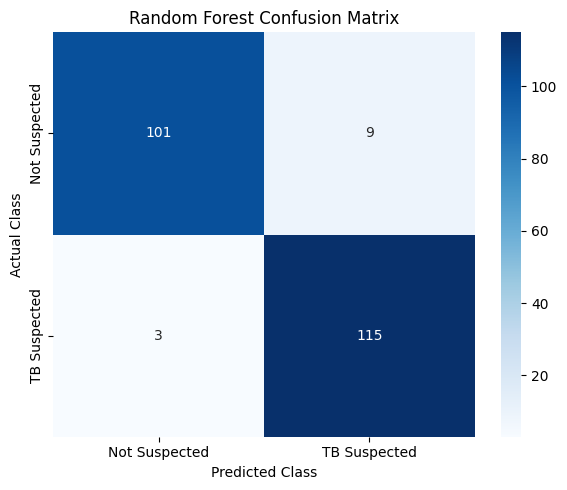

In [54]:
# ============================================================
# CELL 39: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Suspected", "TB Suspected"],
    yticklabels=["Not Suspected", "TB Suspected"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

In [55]:
## Final Model Selection

##After comparing multiple machine learning algorithms, the Random Forest
#classifier was selected as the final predictive model for the proposed Tuberculosis Risk Prediction System.

# Random Forest was selected because it provided strong predictive performance across the evaluation metrics, including accuracy, precision, recall, F1-score, and ROC-AUC.

#The model was subsequently integrated into an interactive Gradio dashboard. SHAP was incorporated to provide patient-level explanations of model predictions, while the dashboard presents the model-estimated risk and project-defined risk bands.

#The risk bands used in the dashboard are demonstration thresholds for this academic project and are not clinically validated diagnostic thresholds.

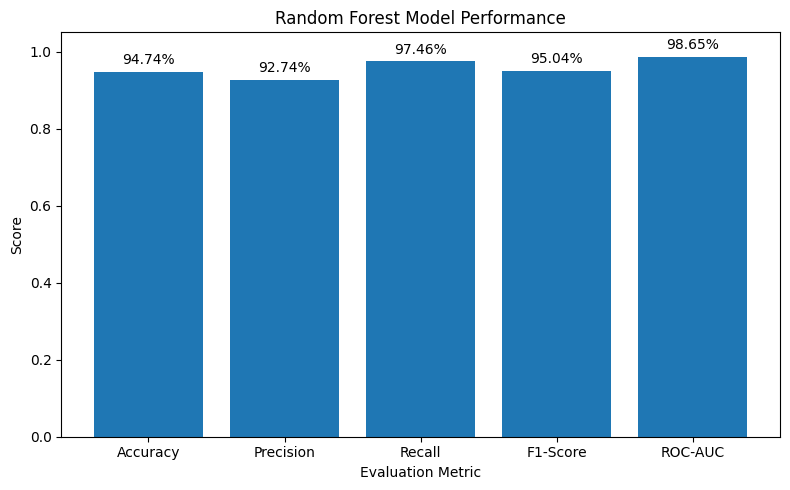

In [59]:
# ============================================================
# CELL 40: MODEL PERFORMANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

metrics = final_results["Metric"]
scores = final_results["Score"]

plt.figure(figsize=(8, 5))

bars = plt.bar(metrics, scores)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.title("Random Forest Model Performance")

# Display values on top of bars
for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        score + 0.02,
        f"{score:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# KDD / Predictive Modelling Process Summary

The proposed Tuberculosis Risk Prediction System follows the major stages of
the Knowledge Discovery in Databases (KDD) and predictive modelling process.

| Stage | Implementation in the Project |
|---|---|
| Problem Identification | Predict TB risk from clinical, demographic, lifestyle and exposure-related factors to support early screening. |
| Data Selection | Selected a tuberculosis-related dataset containing patient symptoms, clinical indicators and exposure factors. |
| Data Understanding | Examined dataset dimensions, feature types, target classes, unique values and class distribution. |
| Data Cleaning | Removed unnecessary columns, formatting columns and invalid/empty records; checked missing values and duplicates. |
| Data Transformation | Converted numerical and categorical variables into machine-learning-compatible representations using preprocessing pipelines. |
| Exploratory Data Analysis | Analysed target distribution and examined relationships among the input variables. |
| Feature Preparation | Separated the target variable from predictor variables and excluded Patient ID from model training. |
| Model Development | Trained and evaluated multiple classification algorithms including Logistic Regression, Decision Tree, Random Forest, AdaBoost, Naive Bayes and Neural Network. |
| Model Selection | Selected Random Forest based on its overall predictive performance. |
| Model Evaluation | Evaluated the selected model using Accuracy, Precision, Recall, F1-Score, ROC-AUC and a Confusion Matrix. |
| Explainable AI | Applied SHAP to identify patient-level features contributing to individual predictions. |
| Prediction & Decision Support | Integrated the Random Forest model into an interactive Gradio dashboard for patient-level risk estimation. |
| Clinical Action Guidance | Added project-defined guidance to encourage further clinical assessment for high model-estimated risk. |
| Interpretation | Results are interpreted as academic predictive analytics outputs and not as clinical diagnosis. |